In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from optimizer import grid_search, strategy_compare

In [3]:
STRATEGIES = {
    "BuyHold": {"minimum_profit": np.inf, "minimum_loss": -np.inf},
    "Default": {},
    "Experimental1": {"cooldown_long": 180.0, "cooldown_short": 90.0},
}

In [4]:
df_prices = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_prices

,BTC,ETH,SOL,XRP,ADA,DOT,LINK,XLM,XMR
Date,,,,,,,,,
2014-09-17,457.334015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-18,424.440002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-19,394.795990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-20,408.903992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-21,398.821014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
2026-10-19,81853.539062,2404.815186,104.926231,1.302713,0.217995,1.153126,12.043903,0.177571,605.426392
2026-10-20,82941.000000,2446.730713,106.422340,1.334452,0.223782,1.149771,12.320927,0.181960,600.929504
2026-10-21,84011.968750,2470.766113,106.793655,1.363619,0.224979,1.141323,12.484719,0.183488,622.434082


# COMPARE

In [5]:
history_compare = strategy_compare(
    prices=df_prices,
    strategies=STRATEGIES,
    n_boot=100,
    sample_size=10,
    sequence_length=365 * 4,
)

100%|██████████| 3/3 [02:14<00:00, 44.99s/it]


In [6]:
history_compare

,strategy,Target,Cash_spent,Realized_cash,Portfolio,Invested,Total_value,Bull_history,MDD,Survival,RoAC,iteration
0,BuyHold,DOT,2059,0,986,2059,986,11,-1642,98.500000,-27,1
1,BuyHold,XLM,2069,0,2054,2069,2054,48,-9360,0.000000,65,1
2,BuyHold,DOT,2069,0,508,2069,508,26,-1893,0.000000,-15,1
3,BuyHold,BTC,2069,0,8619,2069,8619,92,-11261,257.000000,289,1
4,BuyHold,ADA,2059,0,24348,2059,24348,50,-44741,110.000000,498,1
...,...,...,...,...,...,...,...,...,...,...,...,...
2995,Experimental1,XMR,2059,2205,1250,1170,3455,82,-2442,39.333333,71,100
2996,Experimental1,XMR,2069,272,1806,1940,2078,31,-590,30.636364,12,100
2997,Experimental1,XRP,2059,5681,664,628,6345,91,-1901,0.000000,132,100
2998,Experimental1,ETH,2059,917,2424,1744,3341,71,-1359,101.750000,91,100


In [7]:
compare_res = history_compare.groupby("strategy").agg(
    RoAC_mean=("RoAC", "mean"),
    RoAC_median=("RoAC", "median"),
    MDD_mean=("MDD", "mean"),
    MDD_median=("MDD", "median"),
    Portfolio_mean=("Portfolio", "mean"),
    Portfolio_median=("Portfolio", "median"),
    Cash_spent_mean=("Cash_spent", "mean"),
    Cash_spent_median=("Cash_spent", "median"),
    Total_value_mean=("Total_value", "mean"),
    Total_value_median=("Total_value", "median"),
    Total_value_low=("Total_value", lambda s: np.percentile(s, 25)),
    Total_value_high=("Total_value", lambda s: np.percentile(s, 75)),
)

compare_res['Uncle'] = compare_res['MDD_mean'] / compare_res['Total_value_mean']
compare_res['Profit_coef'] = compare_res['Total_value_mean'] / compare_res['Cash_spent_mean']
compare_res.sort_values("RoAC_mean", ascending=False).style.background_gradient(cmap="RdYlGn", axis=0).format("{:.2f}")

,RoAC_mean,RoAC_median,MDD_mean,MDD_median,Portfolio_mean,Portfolio_median,Cash_spent_mean,Cash_spent_median,Total_value_mean,Total_value_median,Total_value_low,Total_value_high,Uncle,Profit_coef
strategy,,,,,,,,,,,,,,
BuyHold,155.02,59.00,-9754.10,-4702.00,5747.42,3462.00,2064.77,2069.00,5747.42,3462.00,2093.00,6256.50,-1.70,2.78
Experimental1,126.19,80.50,-3264.68,-2452.00,1768.79,1435.50,2326.25,2316.00,6479.79,5003.00,3426.25,8388.50,-0.50,2.79
Default,88.66,75.00,-1562.84,-1377.00,1271.40,1076.00,2365.27,2326.00,5317.64,4679.00,3533.00,6569.75,-0.29,2.25


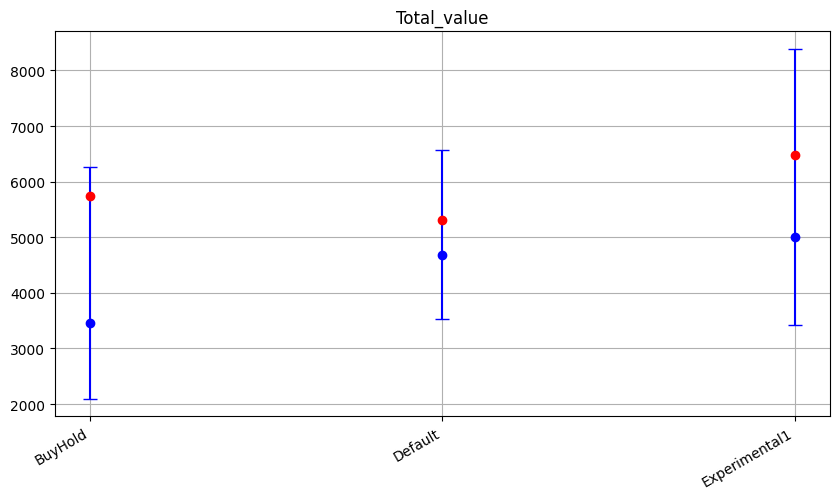

In [8]:
metric = "Total_value"

plt.figure(figsize=(10, 5))

median = compare_res[f"{metric}_median"]
mean = compare_res[f"{metric}_mean"]
low = compare_res[f"{metric}_low"]
high = compare_res[f"{metric}_high"]

plt.errorbar(
    median.index,
    median.values,
    yerr=[median - low, high - median],
    fmt="o",
    capsize=5,
    label="median",
    color="blue",
)
plt.errorbar(
    mean.index,
    mean.values,
    fmt="o",
    capsize=5,
    label="mean",
    color="red",
)
plt.title(metric)
plt.xticks(rotation=30, ha="right")
plt.grid()
plt.show()